# Heart Disease Prediction — Data Understanding

## Objective

The objective of this notebook is to understand the Heart Disease dataset before performing data cleaning, exploratory data analysis, preprocessing, and machine learning.

### Key tasks
- Load and inspect the dataset
- Understand dataset dimensions and structure
- Understand feature meanings and data types
- Identify missing values
- Identify duplicate records
- Analyze unique values
- Understand the target variable
- Identify potential data quality issues

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/heart_disease.csv")

In [5]:
df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [6]:
df.tail()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
915,916,54,Female,VA Long Beach,asymptomatic,127.0,333.0,True,st-t abnormality,154.0,False,0.0,NaN,NaN,NaN,1
916,917,62,Male,VA Long Beach,typical angina,NaN,139.0,False,st-t abnormality,NaN,NaN,NaN,NaN,NaN,NaN,0
917,918,55,Male,VA Long Beach,asymptomatic,122.0,223.0,True,st-t abnormality,100.0,False,0.0,NaN,NaN,fixed defect,2
918,919,58,Male,VA Long Beach,asymptomatic,NaN,385.0,True,lv hypertrophy,NaN,NaN,NaN,NaN,NaN,NaN,0
919,920,62,Male,VA Long Beach,atypical angina,120.0,254.0,False,lv hypertrophy,93.0,True,0.0,NaN,NaN,NaN,1


In [7]:
df.shape

(920, 16)

In [10]:
df.columns.tolist()

['id',
 'age',
 'sex',
 'dataset',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalch',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'num']

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


In [13]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


## From above we can say

# Age 
- min age for heart disease is 28

# trestbps
- bp should not be 0 

# chol
- cholestrol should range between 100-300 here it is 0-603

# oldpeak
- Negative values may need investigation. Positive values >~3 can be relatively high.



| Column | What to check | Your values | What it means |
|---|---|---:|---|
| **age** | Normal human range | 28–77 | ✅ Looks reasonable. Mean ~53.5 |
| **trestbps** | Resting BP | 0–200 | ⚠️ **0 is suspicious/invalid**. Adult BP normally shouldn't be 0. Check those rows. |
| **chol** | Cholesterol | 0–603 | ⚠️ **0 is suspicious/invalid**. Typical total cholesterol is roughly **100–300 mg/dL**; >300 should be investigated as high/outlier. |
| **thalch** | Maximum heart rate | 0–202 | ⚠️ **0 is suspicious/invalid**. For adults, roughly **60–200** is plausible, depending on age/condition. |
| **oldpeak** | ST depression | -2.6–6.2 | ⚠️ Negative values may need investigation. Positive values >~3 can be relatively high. |
| **ca** | Number of major vessels | 0–3 | ✅ Expected range. But values should generally be **0,1,2,3**; check missing values separately. |
| **num** | Heart disease severity/target | 0–4 | ✅ Expected categorical target. Check how many observations belong to each class. |


In [14]:
df.isnull().sum()

id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

In [16]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

ca          66.413043
thal        52.826087
slope       33.586957
fbs          9.782609
oldpeak      6.739130
trestbps     6.413043
exang        5.978261
thalch       5.978261
chol         3.260870
restecg      0.217391
cp           0.000000
dataset      0.000000
id           0.000000
age          0.000000
sex          0.000000
num          0.000000
dtype: float64

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df[df.duplicated(keep=False)].sort_values(by="id")

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num


In [20]:
categorical_columns = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


sex
sex
Male      726
Female    194
Name: count, dtype: int64

cp
cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46
Name: count, dtype: int64

fbs
fbs
False    692
True     138
NaN       90
Name: count, dtype: int64

restecg
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
NaN                   2
Name: count, dtype: int64

exang
exang
False    528
True     337
NaN       55
Name: count, dtype: int64

slope
slope
flat           345
NaN            309
upsloping      203
downsloping     63
Name: count, dtype: int64

ca
ca
NaN    611
0.0    181
1.0     67
2.0     41
3.0     20
Name: count, dtype: int64

thal
thal
NaN                  486
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64


In [28]:
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalch",
    "oldpeak"
]

for col in numerical_columns:
    print(f"\n{col}")
    print("Min:", df[col].min())
    print("Max:", df[col].max())
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())


age
Min: 28
Max: 77
Mean: 53.51086956521739
Median: 54.0

trestbps
Min: 0.0
Max: 200.0
Mean: 132.13240418118468
Median: 130.0

chol
Min: 0.0
Max: 603.0
Mean: 199.13033707865168
Median: 223.0

thalch
Min: 60.0
Max: 202.0
Mean: 137.5456647398844
Median: 140.0

oldpeak
Min: -2.6
Max: 6.2
Mean: 0.8787878787878788
Median: 0.5


In [29]:
df["num"].value_counts().sort_index()

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

In [30]:
df["num"].value_counts(normalize=True).sort_index() * 100

num
0    44.673913
1    28.804348
2    11.847826
3    11.630435
4     3.043478
Name: proportion, dtype: float64

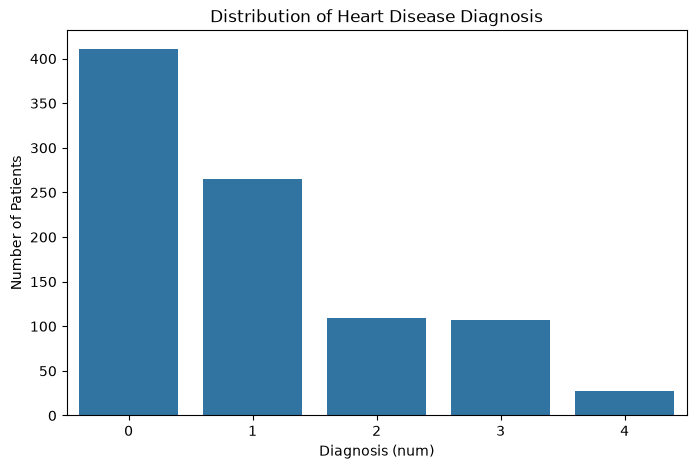

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="num")

plt.title("Distribution of Heart Disease Diagnosis")
plt.xlabel("Diagnosis (num)")
plt.ylabel("Number of Patients")

plt.show()

In [32]:
df["id"].nunique(), len(df)

(920, 920)

In [34]:
df["dataset"].value_counts(dropna=False)

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [36]:
df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [37]:
df["dataset"].value_counts()

dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

In [38]:
df.groupby("dataset")["num"].value_counts(normalize=True)

dataset        num
Cleveland      0      0.542763
               1      0.180921
               2      0.118421
               3      0.115132
               4      0.042763
Hungary        0      0.638225
               1      0.361775
Switzerland    1      0.390244
               2      0.260163
               3      0.243902
               0      0.065041
               4      0.040650
VA Long Beach  1      0.280000
               0      0.255000
               3      0.210000
               2      0.205000
               4      0.050000
Name: proportion, dtype: float64

In [39]:
df[df["oldpeak"] < 0]

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
603,604,38,Male,Switzerland,non-anginal,100.0,0.0,NaN,normal,179.0,False,-1.1,upsloping,NaN,NaN,0
609,610,42,Male,Switzerland,asymptomatic,105.0,0.0,NaN,normal,128.0,True,-1.5,downsloping,NaN,NaN,1
614,615,45,Male,Switzerland,non-anginal,110.0,0.0,NaN,normal,138.0,False,-0.1,upsloping,NaN,NaN,0
615,616,46,Male,Switzerland,asymptomatic,100.0,0.0,NaN,st-t abnormality,133.0,False,-2.6,flat,NaN,NaN,1
629,630,51,Male,Switzerland,asymptomatic,130.0,0.0,NaN,normal,170.0,False,-0.7,upsloping,NaN,NaN,2
653,654,56,Male,Switzerland,non-anginal,125.0,0.0,NaN,normal,98.0,False,-2.0,flat,NaN,reversable defect,2
655,656,56,Male,Switzerland,asymptomatic,115.0,0.0,NaN,st-t abnormality,82.0,False,-1.0,upsloping,NaN,NaN,1
656,657,56,Male,Switzerland,asymptomatic,120.0,0.0,False,st-t abnormality,100.0,True,-1.0,downsloping,NaN,reversable defect,2
691,692,62,Male,Switzerland,typical angina,120.0,0.0,NaN,lv hypertrophy,134.0,False,-0.8,flat,2.0,NaN,1
694,695,62,Male,Switzerland,asymptomatic,115.0,0.0,NaN,normal,72.0,True,-0.5,flat,NaN,normal,1


# Conslusion

Dataset
│
├── 920 observations
├── 16 columns
│
├── id
│   └── Identifier → remove from modeling
│
├── dataset
│   └── Source information → investigate
│
├── Clinical features
│   └── candidate predictors
│
├── Missing values
│   ├── ca       → 66.4%
│   ├── thal     → 52.8%
│   ├── slope    → 33.6%
│   └── others  → lower missingness
│
├── Invalid-looking values
│   ├── trestbps = 0
│   └── chol = 0
│
├── Duplicates
│   └── None
│
└── Target
    └── num → eventually convert to binary

In [ ]:
hello